# DNA/RecA: full-force Marko–Siggia inverse mechanics

## Problem
Infer shared persistence length/stretch modulus and separate DNA contour lengths from calibrated real C-Trap force–extension observations. Both Control and RecA curves are mandatory. The author dataset is real; reconstructed elastic parameters are method references, not independent biological truth.

## Data
Keep1318Control and1329RecA native samples. The fixed observed-force≤30pNsupport contains884and1030points. Force is pN; extension is micrometres. No estimated parameter is used to calibrate these data. Instrument metadata has26°C, while the author’s model fixes kT=4.11pN nm; preserve and disclose both.

In [1]:
from pathlib import Path
import sys,time,json,numpy as np
ROOT=Path.cwd()
if not (ROOT/'src').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.solvers import reconstruct,submission
from src.visualization import make_figures
import matplotlib.pyplot as plt
data=load_data(ROOT/'data/raw_data.npz')
print({n:(len(data['force_'+n]),int(data['mask_'+n].sum())) for n in ['control','reca']})

{'control': (1318, 884), 'reca': (1329, 1030)}


## Physics

The full extensible WLCrelation is F Lp/kT=1/[4(1−u)²]−1/4+u, where u=d/Lc−F/S. Fis force(pN), d/Lc are extension/contour length(µm), Lpis persistence length(nm), Sis stretch modulus(pN), kTis thermal energy(pN nm). Analytic cubic inversion selects the physical tensile branch. Its force is zero at zero extension and its stiffness is positive. Independent tests verify the implicit equation and finite-difference Jacobian.

## Method

Actively fit all1914selected observations jointly using the author’s explicit Marko–Siggia force/Jacobian, TRFand unchanged tutorial joint parameter coupling/bounds/initialization. The initial Odijk tutorial was rejected because its high-force validity range excluded much of its supplied fit domain. It remains a labeled historical comparison below. Rebinding was authorized after a fresh original MSexecution; it is not called an unchanged Odijk reproduction.

In [2]:
start=time.perf_counter();fit=reconstruct(data);runtime=time.perf_counter()-start
assert fit.success
fresh=submission(fit,data)
print('Full fresh fit runtime:',runtime)
print('Lp[nm], Lc_control[µm], S[pN], Lc_RecA[µm]:',fit.x)
print('Jacobian rank:',np.linalg.matrix_rank(fit.jac),'of4')
print('Residual cost (half sum pN²):',fit.cost)

Full fresh fit runtime: 0.017705500009469688
Lp[nm], Lc_control[µm], S[pN], Lc_RecA[µm]: [ 67.40367719   2.73546319 993.30217952   2.99263677]
Jacobian rank: 4 of4
Residual cost (half sum pN²): 103.25740703081533


## Results
Each selected curve is freshly reconstructed. Original MSand the rejected original Odijk results were computed independently on the same observations. Neither is substituted for fresh output. Low-force residuals and native out-of-domain observations remain visible. Local covariance intervals are conditional diagnostics, not calibrated molecular uncertainty.

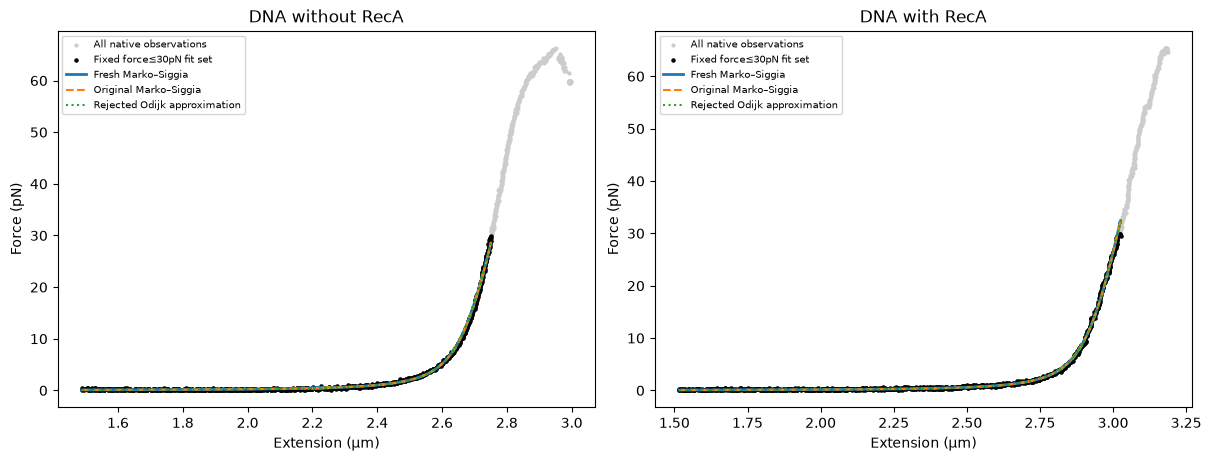

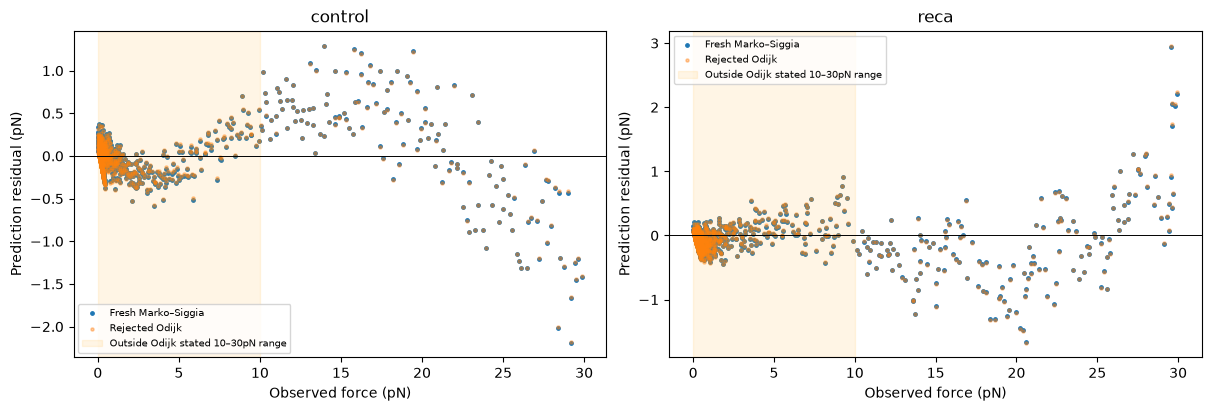

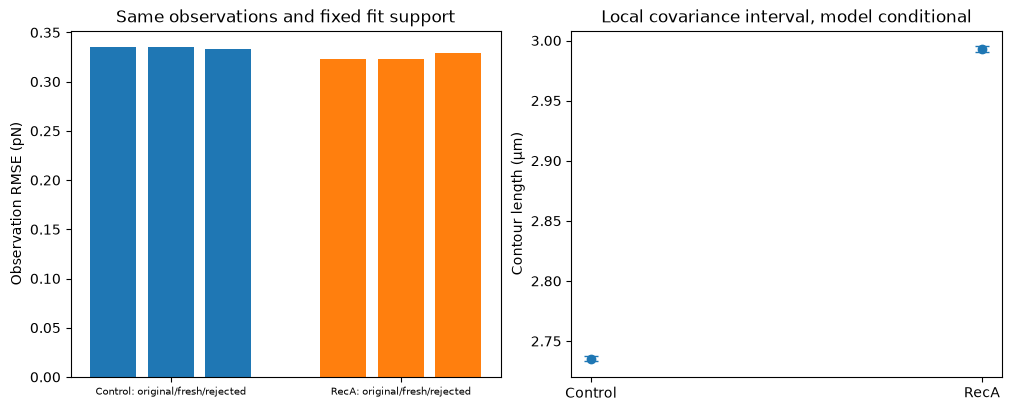

In [3]:
original=np.load(ROOT/'notebooks/reference_outputs/original_method.npz',allow_pickle=False)
rejected=np.load(ROOT/'notebooks/reference_outputs/rejected_odijk.npz',allow_pickle=False)
figures=make_figures(data,fit,original,rejected)
for fig in figures:display(fig)
plt.close('all')

In [4]:
import importlib.util
spec=importlib.util.spec_from_file_location('judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
ref=judge.load_arrays(ROOT/'evaluation/baseline_reference.npz')
bounds=json.loads((ROOT/'evaluation/metrics.json').read_text())['boundaries']
m,passed=judge.score(fresh,ref,{k:data[k][None] for k in ['force_control','force_reca']},bounds)
print(json.dumps(m,indent=2));print('All criteria:',passed);assert passed
print('Neither trap stiffness fit error nor model residual is a supplied independent force precision.')

{
  "persistence_length": 0.0,
  "stretch_modulus": 0.0,
  "contour_lengths": 0.0,
  "predicted_force_control": 0.0,
  "predicted_force_reca": 0.0,
  "observation_rmse_control": 0.3350404173298712,
  "observation_rmse_reca": 0.3227370420212834
}
All criteria: True
Neither trap stiffness fit error nor model residual is a supplied independent force precision.


## Conclusion
The full-force selected method reproduces original MSestimates, with an increased RecAcontour length under the assumed shared elasticity. Observation RMSis about.33pNper condition and includes structured discrepancy. No physical parameter GTor per-point force-noise calibration exists. The rejected Odijk high-force-only diagnostic reaches the80nmbound; it is disclosed rather than repaired by changing bounds or deleting samples. The task evaluates a finite, physically admissible conditional estimator without claiming that RecA changes only contour length in reality.